# Project 1 — Bank Marketing: Predicting Term-Deposit Subscription

**Course:** Data Mining  **Dataset:** `bank-additional-full.csv` (Portuguese bank telephone campaigns, May 2008 – Nov 2010)

**Business goal.** Build and evaluate a model that ranks customers by their probability of subscribing to a term deposit, so the bank can decide *whom to call* in the next campaign.

**Structure of this notebook**

| Section | Assignment task |
|---|---|
| 1. Setup | – |
| 2. Data understanding (EDA) and short data report | Task 1 |
| 3. Data preparation, with justification | Task 1 |
| 4. Majority-class baseline | Task 1 |
| 5. Candidate approaches, evaluation and ranking (≤ 3) | Task 2 |
| 6. Decision threshold and the calls-vs-missed-subscribers trade-off | Task 3 |
| 7. Conclusions and limitations | – |

All random processes use a fixed seed (`RANDOM_STATE = 42`) so results are reproducible. The notebook runs top-to-bottom in a few minutes on a laptop.

## 1. Setup

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (train_test_split, StratifiedKFold, RandomizedSearchCV,
                                     cross_validate, cross_val_predict)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, brier_score_loss,
                             confusion_matrix, roc_curve, precision_recall_curve)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

# Consistent, colour-blind-checked palette (fixed order: one colour per model, never re-cycled)
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100",
     "grey": "#8a8984", "red": "#e34948"}
MODEL_COLORS = {"Logistic Regression": C["blue"], "Random Forest": C["orange"],
                "Gradient Boosting (HGB)": C["aqua"], "Baseline (majority)": C["grey"]}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.titleweight": "bold", "axes.titlesize": 11,
    "axes.labelsize": 10, "legend.frameon": False, "lines.linewidth": 2,
})

DATA_PATH = Path("data") / "bank-additional-full.csv"

## 2. Data understanding (exploratory analysis)

The file is semicolon-separated. The data dictionary (`data/bank-additional-full-README.txt`) groups the 20 inputs into four blocks:

* **Client:** `age`, `job`, `marital`, `education`, `default`, `housing`, `loan`
* **Last contact of this campaign:** `contact`, `month`, `day_of_week`, `duration`
* **Campaign history:** `campaign`, `pdays`, `previous`, `poutcome`
* **Socio-economic context:** `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed`

Target: `y` (yes / no — did the client subscribe?).

In [2]:
df_raw = pd.read_csv(DATA_PATH, sep=";")
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
NUM_COLS = ["age", "duration", "campaign", "pdays", "previous", "emp.var.rate",
            "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
CAT_COLS = ["job", "marital", "education", "default", "housing", "loan",
            "contact", "month", "day_of_week", "poutcome"]

quality = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "n_unique": df_raw.nunique(),
    "n_missing (NaN)": df_raw.isna().sum(),
    "n_'unknown'": [(df_raw[c] == "unknown").sum() if c in CAT_COLS else 0 for c in df_raw.columns],
})
quality["%_'unknown'"] = (100 * quality["n_'unknown'"] / len(df_raw)).round(2)
print("Exact duplicate rows:", df_raw.duplicated().sum())
quality

Exact duplicate rows: 12


,dtype,n_unique,n_missing (NaN),n_'unknown',%_'unknown'
age,int64,78,0,0,0.00
job,str,12,0,330,0.80
marital,str,4,0,80,0.19
education,str,8,0,1731,4.20
default,str,3,0,8597,20.87
housing,str,3,0,990,2.40
loan,str,3,0,990,2.40
contact,str,2,0,0,0.00
month,str,10,0,0,0.00
day_of_week,str,5,0,0,0.00


In [4]:
df_raw[NUM_COLS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41188.0,258.29,259.28,0.00,102.00,180.00,319.00,4918.00
campaign,41188.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41188.0,962.48,186.91,0.00,999.00,999.00,999.00,999.00
previous,41188.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41188.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41188.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41188.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41188.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41188.0,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


### 2.1 Target distribution (class imbalance)

     count   share
y                 
no   36548  0.8873
yes   4640  0.1127


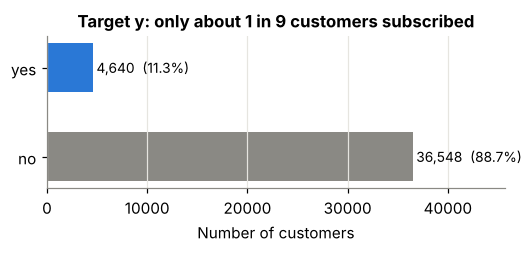

In [5]:
target_counts = df_raw["y"].value_counts()
target_share = df_raw["y"].value_counts(normalize=True)
print(pd.DataFrame({"count": target_counts, "share": target_share.round(4)}))

fig, ax = plt.subplots(figsize=(5, 2.4))
ax.barh(target_counts.index, target_counts.values, color=[C["grey"], C["blue"]], height=0.55)
for i, (v, s) in enumerate(zip(target_counts.values, target_share.values)):
    ax.text(v + 300, i, f"{v:,}  ({s:.1%})", va="center", fontsize=9)
ax.set_xlabel("Number of customers"); ax.set_title("Target y: only about 1 in 9 customers subscribed")
ax.set_xlim(0, target_counts.max() * 1.25); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

### 2.2 Numeric variables

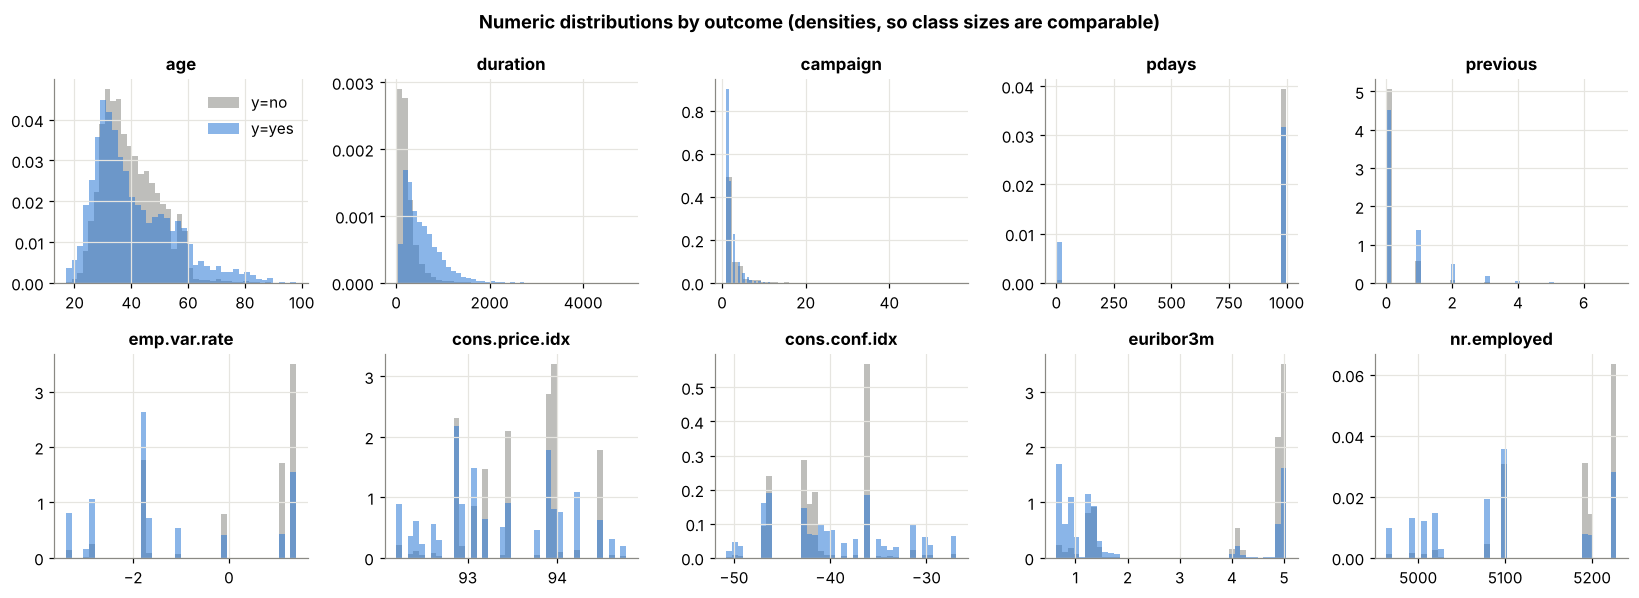

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(15, 5.5))
for ax, col in zip(axes.ravel(), NUM_COLS):
    for lab, colr in [("no", C["grey"]), ("yes", C["blue"])]:
        ax.hist(df_raw.loc[df_raw.y == lab, col], bins=40, density=True, alpha=0.55,
                color=colr, label=f"y={lab}")
    ax.set_title(col)
axes[0, 0].legend()
fig.suptitle("Numeric distributions by outcome (densities, so class sizes are comparable)", fontweight="bold")
plt.tight_layout(); plt.show()

Share of pdays == 999 (never previously contacted): 0.9632
Skewness of count variables:
 duration    3.26
campaign    4.76
previous    3.83
dtype: float64


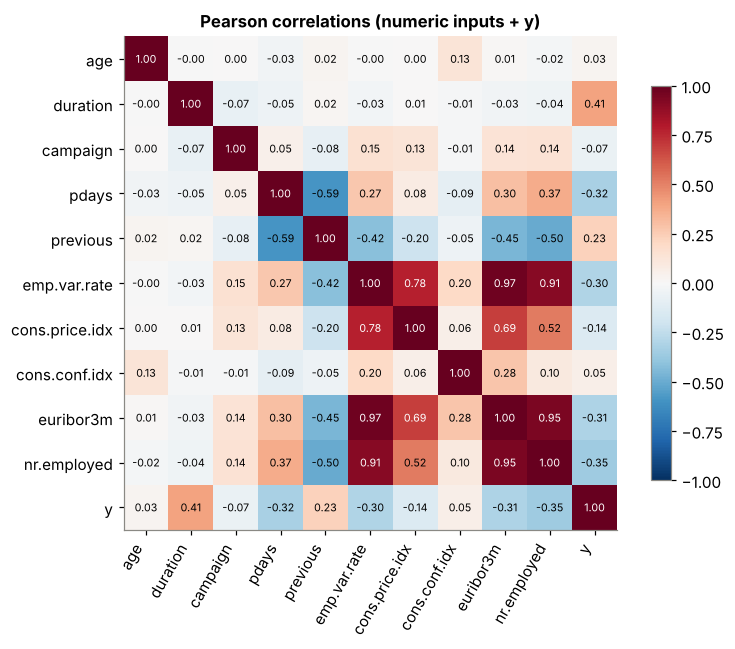

In [7]:
print("Share of pdays == 999 (never previously contacted):", round((df_raw.pdays == 999).mean(), 4))
print("Skewness of count variables:\n", df_raw[["duration", "campaign", "previous"]].skew().round(2))

corr = df_raw[NUM_COLS].assign(y=(df_raw.y == "yes").astype(int)).corr()
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Pearson correlations (numeric inputs + y)")
plt.tight_layout(); plt.show()

### 2.3 Categorical variables: subscription rate per level

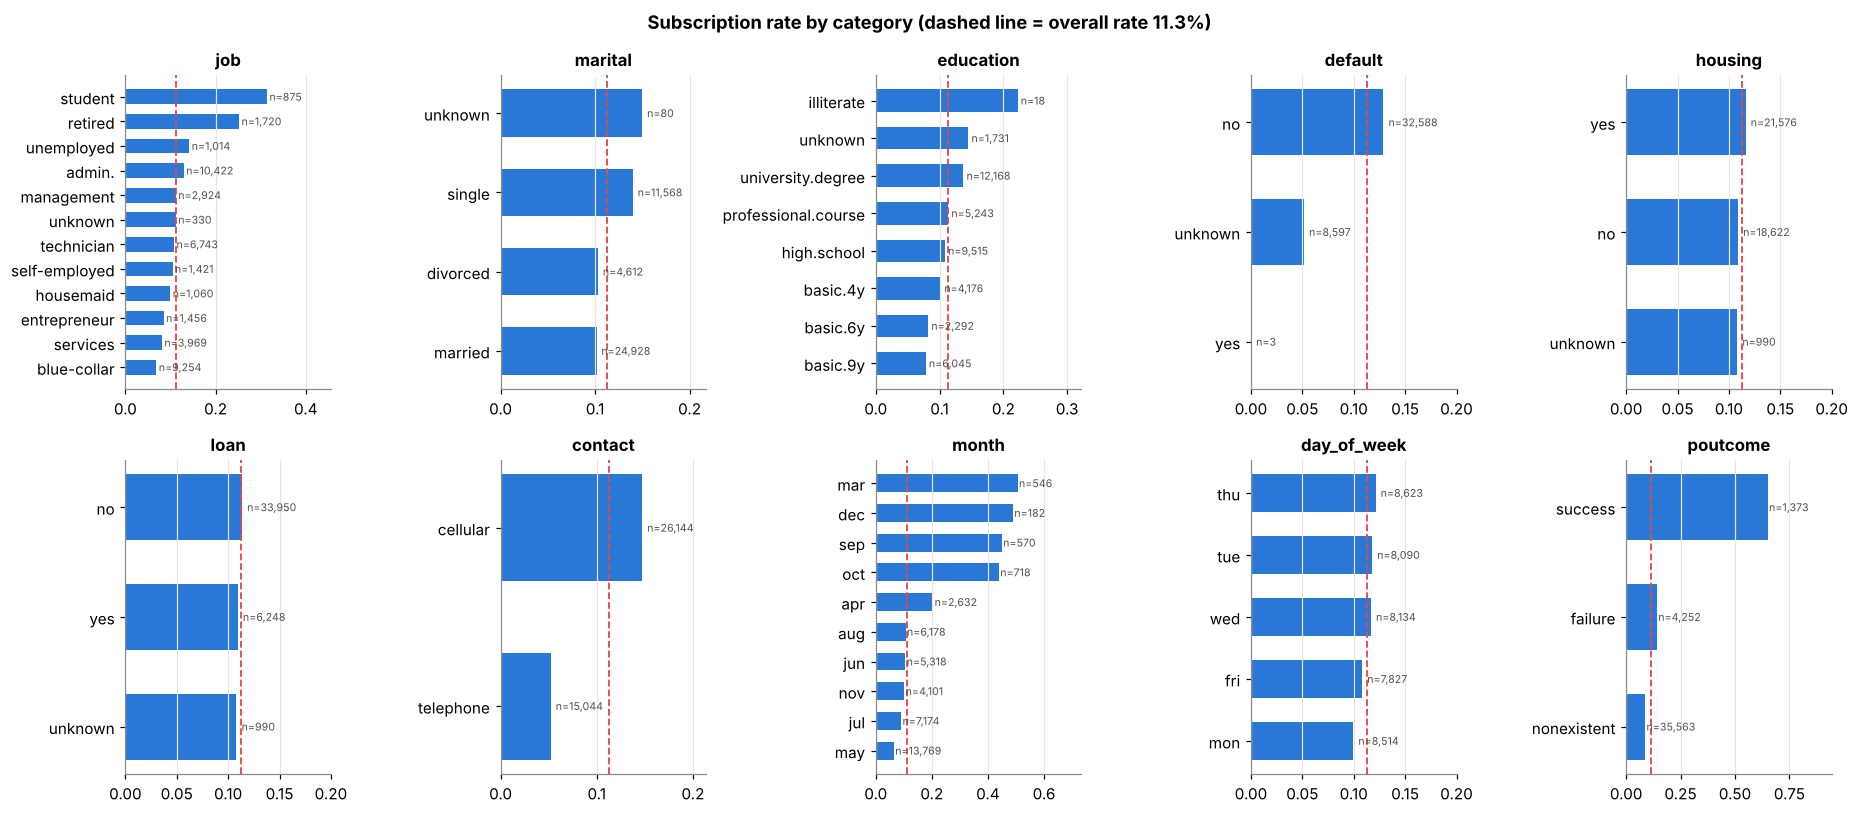

In [8]:
overall_rate = (df_raw.y == "yes").mean()
fig, axes = plt.subplots(2, 5, figsize=(17, 7.5))
for ax, col in zip(axes.ravel(), CAT_COLS):
    rate = df_raw.groupby(col)["y"].apply(lambda s: (s == "yes").mean()).sort_values()
    n = df_raw[col].value_counts().reindex(rate.index)
    ax.barh(rate.index.astype(str), rate.values, color=C["blue"], height=0.6)
    ax.axvline(overall_rate, color=C["red"], lw=1.2, ls="--")
    for i, (r, k) in enumerate(zip(rate.values, n.values)):
        ax.text(r + 0.005, i, f"n={k:,}", va="center", fontsize=7, color="#52514e")
    ax.set_title(col); ax.set_xlim(0, max(rate.max() * 1.45, 0.2)); ax.grid(axis="y", visible=False)
fig.suptitle(f"Subscription rate by category (dashed line = overall rate {overall_rate:.1%})", fontweight="bold")
plt.tight_layout(); plt.show()

### 2.4 The `duration` variable is target leakage

In [9]:
print("Subscription rate when duration == 0:",
      (df_raw.loc[df_raw.duration == 0, "y"] == "yes").mean(), "(n =", (df_raw.duration == 0).sum(), ")")
print("Median call duration (s) by outcome:\n", df_raw.groupby("y")["duration"].median())

Subscription rate when duration == 0: 0.0 (n = 4 )
Median call duration (s) by outcome:
 y
no     163.5
yes    449.0
Name: duration, dtype: float64


### 2.5 Is the file ordered in time?

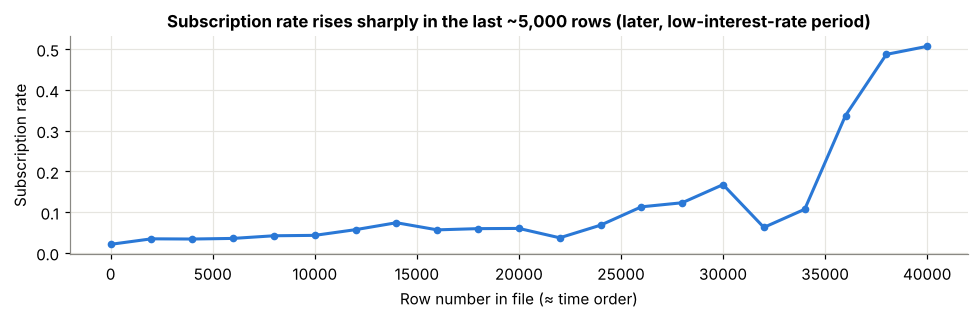

block                 0      1      2      3      4      5      6      7      8      9      10     11     12     13     14     15     16  \
subscription_rate  0.021  0.034  0.034  0.036  0.042  0.043  0.057  0.074  0.056  0.060  0.060  0.037  0.068  0.113  0.123  0.168  0.062   
euribor3m          4.856  4.858  4.857  4.860  4.910  4.960  4.961  4.959  4.962  4.967  4.964  4.964  4.188  3.679  1.418  1.345  1.298   

block                 17     18     19     20  
subscription_rate  0.107  0.337  0.487  0.507  
euribor3m          1.258  1.062  0.707  0.912  


In [10]:
# The rows are stored chronologically (May 2008 -> Nov 2010). The macro indicators
# change in blocks, and the monthly subscription rate moves sharply over the file.
block = np.arange(len(df_raw)) // 2000
trend = df_raw.assign(block=block, yy=(df_raw.y == "yes").astype(int)).groupby("block").agg(
    subscription_rate=("yy", "mean"), euribor3m=("euribor3m", "mean"))
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(trend.index * 2000, trend.subscription_rate, color=C["blue"], marker="o", ms=4)
ax.set_xlabel("Row number in file (≈ time order)"); ax.set_ylabel("Subscription rate")
ax.set_title("Subscription rate rises sharply in the last ~5,000 rows (later, low-interest-rate period)")
plt.tight_layout(); plt.show()
print(trend.round(3).T)

### 2.6 Short data report

* **Size and quality.** 41,188 rows × 21 columns, no `NaN` values and **12 exact duplicate rows**. Missing information is coded as the string `"unknown"` in six categorical columns, most notably `default` (≈ 21 %) and `education` (≈ 4 %).
* **Target is imbalanced.** Only **11.3 %** of customers subscribed (4,640 of 41,188). Accuracy is therefore a misleading metric: a model that always predicts "no" is 88.7 % accurate yet finds no subscribers. We use **PR-AUC (average precision)** as the primary metric, supported by ROC-AUC, recall, precision and the Brier score (probability quality).
* **Leakage.** `duration` is only known *after* the call has ended (a call of 0 s always ends in "no"), so it cannot be used to pick whom to call. It is excluded from the realistic model and used only as an illustrative benchmark.
* **Strongest signals (univariate).** A previous campaign `poutcome = success` (≈ 65 % subscribe vs 11 % overall), `contact = cellular`, the months of **March, September, October and December** (≈ 44 – 51 %, but on few calls) versus **May** (6 %, the busiest month), `job = student / retired`, and the macro-economic indicators: subscriptions are much more common when `euribor3m` and `nr.employed` are low.
* **Special code.** `pdays = 999` means "never contacted before" and covers 96 % of rows. Treated as a number it would distort any distance- or slope-based model, so it must be recoded.
* **Skew and outliers.** `campaign` (up to 56 calls) and `previous` are strongly right-skewed. The values are plausible, not errors, so they are kept and log-transformed for the linear model.
* **Multicollinearity.** `euribor3m`, `emp.var.rate` and `nr.employed` are almost perfectly correlated (|r| > 0.9). Tree models are unaffected; for logistic regression we rely on L2 regularisation and do not interpret individual coefficients causally.
* **Time structure.** The file is in time order and the subscription rate changes strongly over time. A random split measures performance under "similar conditions"; a forward-in-time (rolling-origin) check is reported in Section 5.6.

## 3. Data preparation (with justification)

| Step | Action | Justification |
|---|---|---|
| 1 | Drop the 12 exact duplicate rows | Duplicates add no information and could appear on both sides of a train/test split, inflating scores. |
| 2 | **Drop `duration`** | Target leakage: unknown before the call is made (see 2.4 and the data dictionary). |
| 3 | Keep `"unknown"` as its own category | It is informative (e.g. `default = unknown` customers subscribe less often). Deleting rows would lose ~25 % of data; imputing the mode would invent information. |
| 4 | Recode `pdays` into `prev_contacted` (0/1) + `pdays_bin` (never, 0–3, 4–6, 7+ days) and drop raw `pdays` | Removes the artificial 999 value, which would otherwise act as an extreme outlier. |
| 5 | `log1p` transform of `campaign` and `previous` (logistic regression only) | Reduces right skew so a linear model is not dominated by a few heavy-contact customers. Trees are invariant to monotone transforms. |
| 6 | One-hot encode categoricals (`handle_unknown="ignore"`); standardise numerics | Required by logistic regression (scale-sensitive, no native categoricals); harmless for trees. |
| 7 | Stratified 80/20 train/test split **before** any fitting; all transformations inside `Pipeline` objects | Prevents leakage of test information into preprocessing and keeps the 11.3 % class ratio in both sets. The test set is touched only for final reporting. |
| 8 | Do **not** resample (no SMOTE / undersampling) | We need well-calibrated probabilities for the threshold decision in Task 3. Imbalance is handled instead through imbalance-aware metrics (PR-AUC) and an explicit, cost-based decision threshold. |

In [11]:
df = df_raw.drop_duplicates().reset_index(drop=True)
print("After removing duplicates:", df.shape)

df["y"] = (df["y"] == "yes").astype(int)
df["prev_contacted"] = (df["pdays"] != 999).astype(int)
df["pdays_bin"] = pd.cut(df["pdays"].replace(999, -1), bins=[-2, -0.5, 3, 6, 1000],
                         labels=["never", "0-3", "4-6", "7+"]).astype(str)
df_leak = df.copy()                       # kept only for the duration benchmark in 5.6
df = df.drop(columns=["duration", "pdays"])

NUM_FEATS = ["age", "campaign", "previous", "prev_contacted", "emp.var.rate",
             "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
CAT_FEATS = CAT_COLS + ["pdays_bin"]
X, y = df[NUM_FEATS + CAT_FEATS], df["y"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape}, positive rate {y_train.mean():.4f}")
print(f"Test : {X_test.shape}, positive rate {y_test.mean():.4f}")
pd.crosstab(df["pdays_bin"], df["y"], normalize="index").round(3)

After removing duplicates: (41176, 21)
Train: (32940, 20), positive rate 0.1127
Test : (8236, 20), positive rate 0.1127


y,0,1
pdays_bin,,
0-3,0.348,0.652
4-6,0.339,0.661
7+,0.415,0.585
never,0.907,0.093


In [12]:
def make_preprocessor(log_counts: bool) -> ColumnTransformer:
    # Shared preprocessing. log_counts=True applies log1p to the skewed count variables.
    skewed = ["campaign", "previous"]
    other_num = [c for c in NUM_FEATS if c not in skewed]
    count_steps = ([("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one"))]
                   if log_counts else []) + [("scale", StandardScaler())]
    return ColumnTransformer([
        ("counts", Pipeline(count_steps), skewed),
        ("num", StandardScaler(), other_num),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATS),
    ])

n_features = make_preprocessor(True).fit(X_train).transform(X_train.head()).shape[1]
print("Number of model inputs after one-hot encoding:", n_features)

Number of model inputs after one-hot encoding: 66


## 4. Majority-class baseline

A `DummyClassifier(strategy="most_frequent")` predicts "no" for everyone. Any useful model must beat it on the metrics that matter for *finding subscribers* (recall, precision, PR-AUC), not just on accuracy.

In [13]:
def evaluate(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred),
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, proba),
        "PR-AUC": average_precision_score(y_true, proba),
        "Brier": brier_score_loss(y_true, proba),
    }

baseline = Pipeline([("prep", make_preprocessor(True)),
                     ("clf", DummyClassifier(strategy="most_frequent"))]).fit(X_train, y_train)
p_base = baseline.predict_proba(X_test)[:, 1]
base_res = pd.Series(evaluate(y_test, p_base), name="Baseline (majority)")
print(base_res.round(4))
print("\nConfusion matrix [rows = actual no/yes, cols = predicted no/yes]:\n", confusion_matrix(y_test, (p_base >= .5).astype(int)))

Accuracy     0.8873
Precision    0.0000
Recall       0.0000
F1           0.0000
ROC-AUC      0.5000
PR-AUC       0.1127
Brier        0.1127
Name: Baseline (majority), dtype: float64

Confusion matrix [rows = actual no/yes, cols = predicted no/yes]:
 [[7308    0]
 [ 928    0]]


**Interpretation.** The baseline reaches **≈ 88.7 % accuracy** while identifying **zero** subscribers (recall = 0). Its PR-AUC equals the positive rate (≈ 0.113) and its ROC-AUC is 0.5, i.e. no ranking ability. These are the reference values that the models below must beat. The baseline also shows why accuracy alone cannot be used to judge models on this problem.

## 5. Candidate approaches, evaluation and ranking (Task 2)

### 5.1 Why these three approaches?

| Approach | Why it suits this problem | Known weaknesses |
|---|---|---|
| **Logistic Regression (L2)** | Standard, interpretable benchmark for binary response modelling in marketing; outputs probabilities directly; fast; coefficients/odds ratios are easy to explain to the marketing team. | Assumes a linear log-odds relationship; cannot capture interactions (e.g. month × macro context) unless engineered. |
| **Random Forest** | Captures non-linearities and interactions automatically; robust to outliers, skew and collinear macro variables; little tuning needed. | Probabilities are often poorly calibrated (pulled away from 0 and 1); larger and slower; less interpretable. |
| **Gradient Boosting (HistGradientBoosting)** | Usually the strongest family on tabular data; sequentially corrects errors; handles interactions; fast histogram implementation scales to 40k rows; optimises log-loss so probabilities tend to be well calibrated. | More hyper-parameters; risk of overfitting if not tuned with cross-validation; less transparent. |

Other options were considered and rejected: *k*-NN and SVM scale poorly and need careful distance design for 60+ mostly one-hot inputs; a single decision tree is unstable and is dominated by the two ensembles; Naive Bayes assumes independence that is clearly violated by the collinear macro variables.

### 5.2 Evaluation protocol

* **Hyper-parameter tuning:** `RandomizedSearchCV` on the training set only, 3-fold stratified CV, scoring = average precision (PR-AUC).
* **Model comparison:** the tuned models are re-assessed with **5-fold stratified CV** on the training set (mean ± standard deviation) and then **once** on the untouched test set, with **bootstrap 95 % confidence intervals**.
* **Ranking criteria (in order):** (1) PR-AUC — directly measures how well subscribers are ranked at the top of the call list; (2) ROC-AUC; (3) Brier score — probability quality, needed for the threshold in Task 3; (4) stability across folds; (5) interpretability and cost.

In [14]:
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

candidates = {
    "Logistic Regression": (
        Pipeline([("prep", make_preprocessor(True)),
                  ("clf", LogisticRegression(max_iter=3000, solver="lbfgs"))]),
        {"clf__C": np.logspace(-3, 1, 20)}, 8),
    "Random Forest": (
        Pipeline([("prep", make_preprocessor(False)),
                  ("clf", RandomForestClassifier(n_estimators=250, n_jobs=-1, random_state=RANDOM_STATE))]),
        {"clf__max_depth": [6, 8, 10, 12, 16, None], "clf__min_samples_leaf": [1, 5, 10, 20, 40],
         "clf__max_features": ["sqrt", 0.3, 0.5]}, 8),
    "Gradient Boosting (HGB)": (
        Pipeline([("prep", make_preprocessor(False)),
                  ("clf", HistGradientBoostingClassifier(random_state=RANDOM_STATE, early_stopping=False))]),
        {"clf__learning_rate": [0.03, 0.05, 0.1], "clf__max_iter": [150, 250, 400],
         "clf__max_leaf_nodes": [8, 15, 31], "clf__min_samples_leaf": [20, 50, 100],
         "clf__l2_regularization": [0.0, 0.5, 1.0]}, 10),
}

tuned, tuning_summary = {}, []
for name, (pipe, grid, n_iter) in candidates.items():
    t0 = time.time()
    search = RandomizedSearchCV(pipe, grid, n_iter=n_iter, scoring="average_precision", cv=cv3,
                                random_state=RANDOM_STATE, n_jobs=-1, refit=True)
    search.fit(X_train, y_train)
    tuned[name] = search.best_estimator_
    best = {k.replace("clf__", ""): v for k, v in search.best_params_.items()}
    tuning_summary.append({"Model": name, "Best CV PR-AUC (3-fold)": round(search.best_score_, 4),
                           "Best hyper-parameters": best, "Tuning time (s)": round(time.time() - t0, 1)})
pd.DataFrame(tuning_summary).set_index("Model")

,Best CV PR-AUC (3-fold),Best hyper-parameters,Tuning time (s)
Model,,,
Logistic Regression,0.4480,{'C': 1.438449888287663},3.0
Random Forest,0.4623,"{'min_samples_leaf': 10, 'max_features': 0.3, ...",67.3
Gradient Boosting (HGB),0.4669,"{'min_samples_leaf': 50, 'max_leaf_nodes': 15,...",34.6


### 5.3 Cross-validated comparison on the training set (5-fold)

In [15]:
scoring = {"PR-AUC": "average_precision", "ROC-AUC": "roc_auc", "Brier": "neg_brier_score"}
cv_rows, cv_folds = [], {}
for name, model in tuned.items():
    res = cross_validate(model, X_train, y_train, cv=cv5, scoring=scoring, n_jobs=-1)
    cv_folds[name] = res["test_PR-AUC"]
    cv_rows.append({"Model": name,
                    "PR-AUC mean": res["test_PR-AUC"].mean(), "PR-AUC sd": res["test_PR-AUC"].std(),
                    "ROC-AUC mean": res["test_ROC-AUC"].mean(), "ROC-AUC sd": res["test_ROC-AUC"].std(),
                    "Brier mean": -res["test_Brier"].mean(),
                    "Fit time per fold (s)": res["fit_time"].mean()})
cv_table = pd.DataFrame(cv_rows).set_index("Model").sort_values("PR-AUC mean", ascending=False)
cv_table.round(4)

,PR-AUC mean,PR-AUC sd,ROC-AUC mean,ROC-AUC sd,Brier mean,Fit time per fold (s)
Model,,,,,,
Gradient Boosting (HGB),0.4703,0.0143,0.8016,0.0086,0.0769,1.8957
Random Forest,0.4672,0.0156,0.7990,0.0104,0.0771,3.3335
Logistic Regression,0.4499,0.0133,0.7890,0.0070,0.0787,0.1863


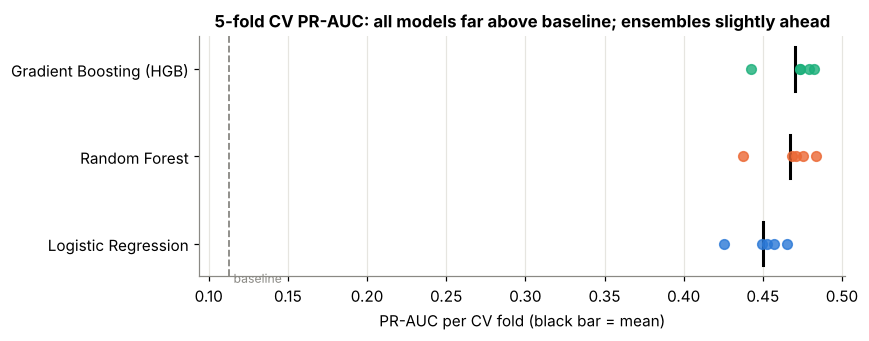

Gradient Boosting (HGB) − Random Forest: mean PR-AUC diff = +0.0031; 4/5 folds favour Gradient Boosting (HGB)
Gradient Boosting (HGB) − Logistic Regression: mean PR-AUC diff = +0.0203; 5/5 folds favour Gradient Boosting (HGB)
Random Forest − Logistic Regression: mean PR-AUC diff = +0.0173; 5/5 folds favour Random Forest


In [16]:
fig, ax = plt.subplots(figsize=(8, 3.2))
names = list(cv_table.index)[::-1]
for i, n in enumerate(names):
    ax.scatter(cv_folds[n], [i] * 5, color=MODEL_COLORS[n], s=40, zorder=3, alpha=0.8)
    ax.plot([cv_folds[n].mean()] * 2, [i - 0.25, i + 0.25], color="black", lw=2)
ax.axvline(y_train.mean(), color=C["grey"], ls="--", lw=1.2)
ax.text(y_train.mean() + 0.003, -0.45, "baseline", color=C["grey"], fontsize=8)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names); ax.grid(axis="y", visible=False)
ax.set_xlabel("PR-AUC per CV fold (black bar = mean)")
ax.set_title("5-fold CV PR-AUC: all models far above baseline; ensembles slightly ahead")
plt.tight_layout(); plt.show()

# Paired comparison: the same folds are used for every model, so fold-wise differences are paired
names_sorted = list(cv_table.index)
for a, b in [(names_sorted[0], names_sorted[1]), (names_sorted[0], names_sorted[2]), (names_sorted[1], names_sorted[2])]:
    d = cv_folds[a] - cv_folds[b]
    print(f"{a} − {b}: mean PR-AUC diff = {d.mean():+.4f}; {np.sum(d > 0)}/5 folds favour {a}")

### 5.4 Final evaluation on the held-out test set (with bootstrap 95 % CIs)

In [17]:
test_proba = {name: m.predict_proba(X_test)[:, 1] for name, m in tuned.items()}
test_proba["Baseline (majority)"] = p_base
test_table = pd.DataFrame({n: evaluate(y_test, p) for n, p in test_proba.items()}).T
test_table = test_table.sort_values("PR-AUC", ascending=False)

rng = np.random.default_rng(RANDOM_STATE)
yt = y_test.to_numpy()
B = 1000
idx = [rng.integers(0, len(yt), len(yt)) for _ in range(B)]
boot = {n: np.array([average_precision_score(yt[i], test_proba[n][i]) for i in idx])
        for n in tuned}
for n in tuned:
    lo, hi = np.percentile(boot[n], [2.5, 97.5])
    test_table.loc[n, "PR-AUC 95% CI"] = f"[{lo:.3f}, {hi:.3f}]"
test_table.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier,PR-AUC 95% CI
Gradient Boosting (HGB),0.9006,0.6580,0.2446,0.3566,0.8149,0.4905,0.0751,"[0.455, 0.527]"
Random Forest,0.8998,0.6459,0.2457,0.3560,0.8107,0.4875,0.0754,"[0.453, 0.523]"
Logistic Regression,0.8987,0.6556,0.2134,0.3220,0.8004,0.4536,0.0779,"[0.419, 0.490]"
Baseline (majority),0.8873,0.0000,0.0000,0.0000,0.5000,0.1127,0.1127,NaN


In [18]:
order = [n for n in test_table.index if n in tuned]
print("Bootstrap distribution of PR-AUC differences on the test set (paired resamples):")
for a, b in [(order[0], order[1]), (order[0], order[2]), (order[1], order[2])]:
    d = boot[a] - boot[b]
    lo, hi = np.percentile(d, [2.5, 97.5])
    print(f"  {a} − {b}: {d.mean():+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]  P(diff>0) = {(d > 0).mean():.2f}")

Bootstrap distribution of PR-AUC differences on the test set (paired resamples):
  Gradient Boosting (HGB) − Random Forest: +0.0031  95% CI [-0.0045, +0.0117]  P(diff>0) = 0.76
  Gradient Boosting (HGB) − Logistic Regression: +0.0369  95% CI [+0.0237, +0.0501]  P(diff>0) = 1.00
  Random Forest − Logistic Regression: +0.0337  95% CI [+0.0203, +0.0467]  P(diff>0) = 1.00


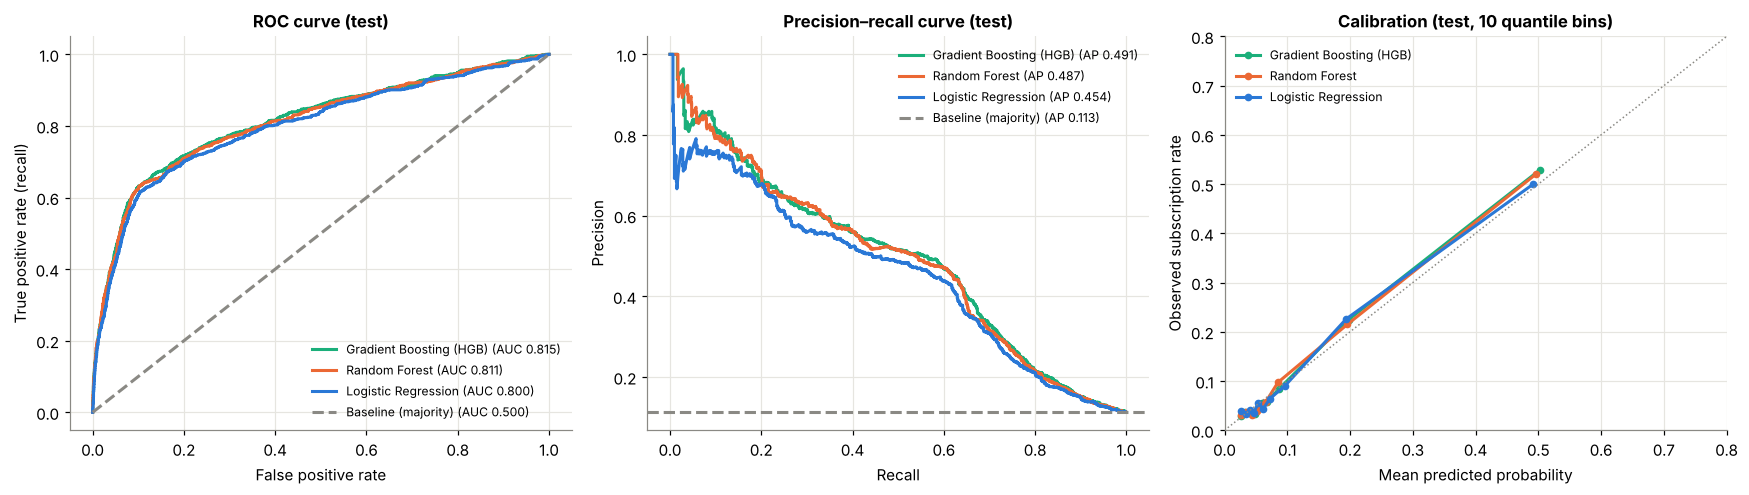

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for n in order + ["Baseline (majority)"]:
    p = test_proba[n]
    fpr, tpr, _ = roc_curve(y_test, p)
    prec, rec, _ = precision_recall_curve(y_test, p)
    ls = "--" if n.startswith("Baseline") else "-"
    axes[0].plot(fpr, tpr, ls=ls, color=MODEL_COLORS[n], label=f"{n} (AUC {roc_auc_score(y_test, p):.3f})")
    if n.startswith("Baseline"):   # a no-skill model has precision = base rate at every recall
        axes[1].axhline(y_test.mean(), ls=ls, color=MODEL_COLORS[n], label=f"{n} (AP {y_test.mean():.3f})")
    else:
        axes[1].plot(rec, prec, color=MODEL_COLORS[n], label=f"{n} (AP {average_precision_score(y_test, p):.3f})")
    if n in tuned:
        frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
        axes[2].plot(mean_pred, frac_pos, marker="o", ms=4, color=MODEL_COLORS[n], label=n)
axes[0].set(xlabel="False positive rate", ylabel="True positive rate (recall)", title="ROC curve (test)")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision–recall curve (test)")
axes[2].plot([0, 1], [0, 1], color=C["grey"], ls=":", lw=1)
axes[2].set(xlabel="Mean predicted probability", ylabel="Observed subscription rate",
            title="Calibration (test, 10 quantile bins)", xlim=(0, 0.8), ylim=(0, 0.8))
for ax in axes: ax.legend(fontsize=8, loc="best")
plt.tight_layout(); plt.show()

### 5.5 Benchmark: how much does the leaky `duration` variable inflate results?

In [20]:
Xl = df_leak[NUM_FEATS + ["duration"] + CAT_FEATS]
Xl_tr, Xl_te = Xl.loc[X_train.index], Xl.loc[X_test.index]
leak_prep = ColumnTransformer([("num", StandardScaler(), NUM_FEATS + ["duration"]),
                               ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATS)])
leak_model = Pipeline([("prep", leak_prep),
                       ("clf", HistGradientBoostingClassifier(random_state=RANDOM_STATE))]).fit(Xl_tr, y_train)
pl = leak_model.predict_proba(Xl_te)[:, 1]
print(f"HGB WITH duration (leaky)    : ROC-AUC {roc_auc_score(y_test, pl):.3f}, PR-AUC {average_precision_score(y_test, pl):.3f}")
for n in order:
    print(f"{n:<29}: ROC-AUC {roc_auc_score(y_test, test_proba[n]):.3f}, PR-AUC {average_precision_score(y_test, test_proba[n]):.3f}  (no duration)")

HGB WITH duration (leaky)    : ROC-AUC 0.952, PR-AUC 0.677
Gradient Boosting (HGB)      : ROC-AUC 0.815, PR-AUC 0.491  (no duration)
Random Forest                : ROC-AUC 0.811, PR-AUC 0.487  (no duration)
Logistic Regression          : ROC-AUC 0.800, PR-AUC 0.454  (no duration)


Including `duration` lifts performance dramatically (ROC-AUC ≈ 0.95), but this is **not achievable in practice**: the call length is only known once the customer has already been called. Reporting such a model would overstate the value of the campaign-selection tool. All models used for ranking and threshold selection exclude it.

### 5.6 Robustness check: does the model work on *future* campaigns? (rolling-origin validation)

The bank will apply the model to the **next** campaign, not to a random sample of past calls. Because the file is in time order (2.5), we also run a **rolling-origin (expanding-window) validation** with `TimeSeriesSplit(n_splits=5)`: each model is trained only on earlier rows and tested on the block that follows.

In [21]:
from sklearn.model_selection import TimeSeriesSplit
tss = TimeSeriesSplit(n_splits=5)
ts_rows = []
for k, (tr, te) in enumerate(tss.split(X), start=1):
    for n in order:
        p = clone(tuned[n]).fit(X.iloc[tr], y.iloc[tr]).predict_proba(X.iloc[te])[:, 1]
        ts_rows.append({"Fold": k, "Train rows": len(tr), "Test positive rate": y.iloc[te].mean(),
                        "Model": n, "ROC-AUC": roc_auc_score(y.iloc[te], p),
                        "PR-AUC": average_precision_score(y.iloc[te], p)})
ts_res = pd.DataFrame(ts_rows)
ts_res["PR-AUC lift (÷ base rate)"] = ts_res["PR-AUC"] / ts_res["Test positive rate"]
display(ts_res.pivot_table(index=["Fold", "Train rows", "Test positive rate"], columns="Model",
                           values="ROC-AUC").round(3).rename_axis(columns="ROC-AUC by model"))
ts_summary = ts_res.groupby("Model")[["ROC-AUC", "PR-AUC", "PR-AUC lift (÷ base rate)"]].mean()
ts_summary["Folds won (ROC-AUC)"] = (ts_res.loc[ts_res.groupby("Fold")["ROC-AUC"].idxmax(), "Model"]
                                     .value_counts().reindex(ts_summary.index).fillna(0).astype(int))
ts_summary.sort_values("ROC-AUC", ascending=False).round(3)

,,ROC-AUC by model,Gradient Boosting (HGB),Logistic Regression,Random Forest
Fold,Train rows,Test positive rate,,,
1,6866,0.045614,0.515,0.525,0.482
2,13728,0.065433,0.533,0.522,0.513
3,20590,0.053483,0.409,0.447,0.425
4,27452,0.127368,0.583,0.668,0.674
5,34314,0.354853,0.637,0.715,0.700


,ROC-AUC,PR-AUC,PR-AUC lift (÷ base rate),Folds won (ROC-AUC)
Model,,,,
Logistic Regression,0.575,0.181,1.236,3
Random Forest,0.559,0.184,1.252,1
Gradient Boosting (HGB),0.536,0.158,1.093,1


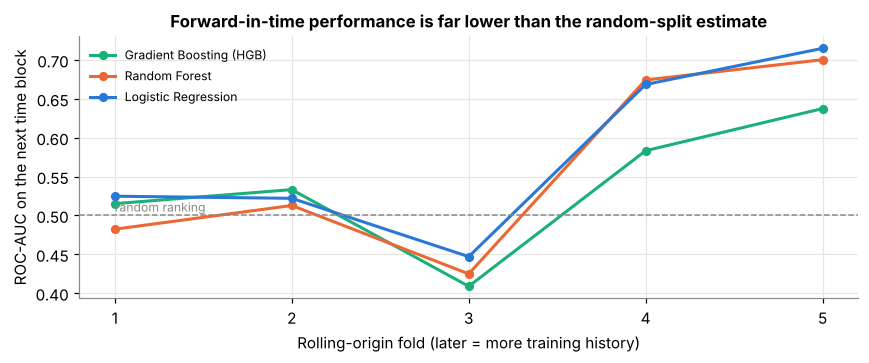

,first 80% min,first 80% max,last 20% min,last 20% max,% of last-20% rows outside training range
emp.var.rate,-1.80,1.40,-3.40,-1.10,35.26
cons.price.idx,92.76,94.46,92.20,94.77,30.61
cons.conf.idx,-50.00,-36.10,-50.80,-26.90,33.45
euribor3m,1.30,5.04,0.63,1.30,98.52
nr.employed,5099.10,5228.10,4963.60,5099.10,60.25


In [22]:
fig, ax = plt.subplots(figsize=(8, 3.4))
for n in order:
    d = ts_res[ts_res.Model == n]
    ax.plot(d["Fold"], d["ROC-AUC"], marker="o", ms=5, color=MODEL_COLORS[n], label=n)
ax.axhline(0.5, color=C["grey"], ls="--", lw=1); ax.text(1, 0.505, "random ranking", color=C["grey"], fontsize=8)
ax.set_xticks(range(1, 6)); ax.set_xlabel("Rolling-origin fold (later = more training history)")
ax.set_ylabel("ROC-AUC on the next time block")
ax.set_title("Forward-in-time performance is far lower than the random-split estimate")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

# Why? The economic indicators of the last period lie OUTSIDE the range seen in training
cut = int(len(df) * 0.8)
macro = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
rng_tab = pd.DataFrame({"first 80% min": X.iloc[:cut][macro].min(), "first 80% max": X.iloc[:cut][macro].max(),
                        "last 20% min": X.iloc[cut:][macro].min(), "last 20% max": X.iloc[cut:][macro].max()})
rng_tab["% of last-20% rows outside training range"] = [
    100 * ((X.iloc[cut:][c] < rng_tab.loc[c, "first 80% min"]) | (X.iloc[cut:][c] > rng_tab.loc[c, "first 80% max"])).mean()
    for c in macro]
rng_tab.round(2)

**What this shows.** The random-split scores (ROC-AUC ≈ 0.80) are optimistic for a forward-looking use. In the early folds the training data cover only a few months, the test months were never seen, and all models are close to random. In the later folds, which have more history, the models become useful again. Here **Logistic Regression and Random Forest generalise forward better than Gradient Boosting**. The table above gives the reason. In the most recent period the macro-economic indicators (e.g. `euribor3m`, `nr.employed`) lie **entirely outside the training range**. Tree ensembles cannot extrapolate: beyond the last split point they predict a constant. Boosting relies most heavily on these indicators, so it suffers most. Logistic regression extrapolates the linear trend ("lower rates → more subscriptions"), which happened to hold. Random forest averages many decorrelated trees that also use client and contact variables, so it degrades less than boosting.

### 5.7 Ranking and justification

The ranking uses two **co-primary** criteria, because the model must both rank customers well *and* keep working on the next campaign:

1. **In-distribution discrimination**: test PR-AUC with bootstrap CI and 5-fold CV PR-AUC (5.3 – 5.4).
2. **Forward-in-time robustness**: mean rolling-origin ROC-AUC / PR-AUC (5.6).

Secondary criteria: calibration (Brier), stability (fold s.d.), interpretability and cost. Differences that are not statistically distinguishable (bootstrap CI includes 0) are treated as ties.

In [23]:
scorecard = pd.DataFrame({
    "CV PR-AUC (mean ± sd)": [f"{cv_table.loc[n, 'PR-AUC mean']:.3f} ± {cv_table.loc[n, 'PR-AUC sd']:.3f}" for n in order],
    "Test PR-AUC [95% CI]": [f"{test_table.loc[n, 'PR-AUC']:.3f} {test_table.loc[n, 'PR-AUC 95% CI']}" for n in order],
    "Test ROC-AUC": [round(test_table.loc[n, "ROC-AUC"], 3) for n in order],
    "Test Brier": [round(test_table.loc[n, "Brier"], 4) for n in order],
    "Rolling-origin ROC-AUC": [round(ts_summary.loc[n, "ROC-AUC"], 3) for n in order],
    "Rolling-origin PR-AUC": [round(ts_summary.loc[n, "PR-AUC"], 3) for n in order],
    "Interpretability": [{"Logistic Regression": "High (coefficients)", "Random Forest": "Medium (importance)",
                          "Gradient Boosting (HGB)": "Medium (importance)"}[n] for n in order],
}, index=order)

FINAL_RANK = ["Random Forest", "Logistic Regression", "Gradient Boosting (HGB)"]
scorecard = scorecard.loc[FINAL_RANK]
scorecard.insert(0, "Rank", [1, 2, 3])
scorecard

,Rank,CV PR-AUC (mean ± sd),Test PR-AUC [95% CI],Test ROC-AUC,Test Brier,Rolling-origin ROC-AUC,Rolling-origin PR-AUC,Interpretability
Random Forest,1,0.467 ± 0.016,"0.487 [0.453, 0.523]",0.811,0.0754,0.559,0.184,Medium (importance)
Logistic Regression,2,0.450 ± 0.013,"0.454 [0.419, 0.490]",0.800,0.0779,0.575,0.181,High (coefficients)
Gradient Boosting (HGB),3,0.470 ± 0.014,"0.491 [0.455, 0.527]",0.815,0.0751,0.536,0.158,Medium (importance)


**Rank 1 — Random Forest.** On the random split it is **statistically tied for best**: its test PR-AUC is within 0.003 of boosting, and the bootstrap CI of the difference includes 0. Both ensembles are significantly better than logistic regression. On forward-in-time validation it is far more robust than boosting and close to logistic regression. It is the only model in the top group on *both* co-primary criteria. Its Brier score is practically equal to the best, so its probabilities are good enough for threshold setting. It captures interactions (e.g. contact type × previous outcome) automatically and needs little tuning.

**Rank 2 — Logistic Regression.** It has the best forward-in-time robustness (highest mean rolling-origin ROC-AUC) and the highest interpretability: odds ratios can be explained to managers and regulators. It ranks below the forest because its in-distribution PR-AUC is **significantly lower** (≈ −0.035, bootstrap CI excludes 0, and it loses on 5/5 CV folds). That means fewer subscribers per call when conditions resemble the training period.

**Rank 3 — Gradient Boosting (HGB).** It has the numerically highest PR-AUC and the best Brier score on the random split, but its advantage over Random Forest is not significant. It is also the **least robust forward in time**, because it leans most heavily on macro indicators whose future values lie outside the training range (5.6). For a model meant to select customers for *future* campaigns, this is the most serious weakness among the three.

> **Note on the decision.** Had we used only the conventional random train/test split, the ranking would have been HGB ≈ RF > LR. The forward-in-time evidence is what moves boosting from first to third. If the bank re-trains every month and conditions stay stable, HGB would be a reasonable alternative to Random Forest.

### 5.8 What drives the selected model? (permutation importance on the test set)

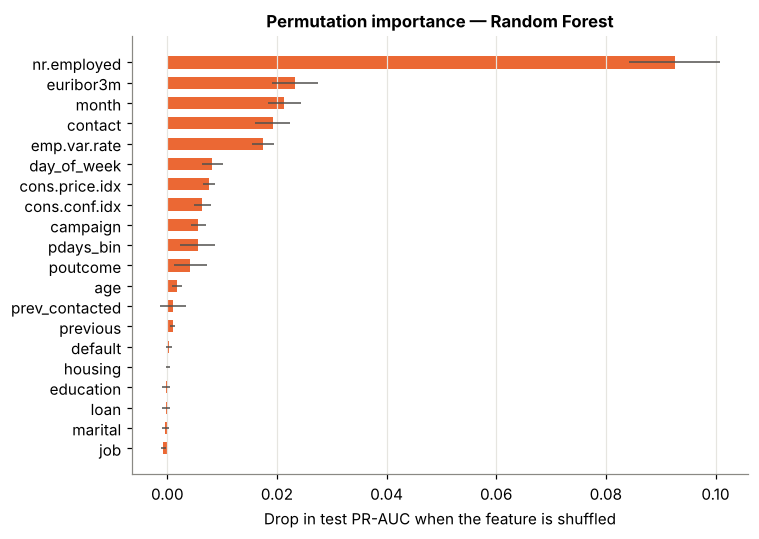

,mean,sd
nr.employed,0.0925,0.0083
euribor3m,0.0233,0.0041
month,0.0213,0.0030
contact,0.0192,0.0032
emp.var.rate,0.0175,0.0021
day_of_week,0.0082,0.0019
cons.price.idx,0.0077,0.0011
cons.conf.idx,0.0064,0.0015


In [24]:
best_name = FINAL_RANK[0]
best_model = tuned[best_name]
pi = permutation_importance(best_model, X_test, y_test, scoring="average_precision",
                            n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"mean": pi.importances_mean, "sd": pi.importances_std},
                   index=X_test.columns).sort_values("mean")
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(imp.index, imp["mean"], xerr=imp["sd"], color=MODEL_COLORS[best_name], height=0.6,
        error_kw={"elinewidth": 1, "ecolor": "#52514e"})
ax.set_xlabel("Drop in test PR-AUC when the feature is shuffled")
ax.set_title(f"Permutation importance — {best_name}"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
imp.sort_values("mean", ascending=False).head(8).round(4)

**Interpretation.** The economic-context indicators dominate: `nr.employed` most of all, then `euribor3m` and `emp.var.rate`. They are followed by `month`, the `contact` channel (mobile vs landline) and `day_of_week`. Client demographics (age, job, education) add comparatively little once the timing and context of the call are known. In practice the model learns *when* and *how* to call as much as *whom* to call. This is useful operationally, but it is also why the model must be re-validated whenever the economic environment changes (5.6).

## 6. Decision threshold and the trade-off between unnecessary calls and missed subscribers (Task 3)

The model outputs a probability; the bank must decide the **cut-off** above which a customer is called.

* A **false positive** = an *unnecessary call* (staff time, cost, risk of annoying the customer).
* A **false negative** = a *missed subscriber* (lost deposit revenue).

Lowering the threshold calls more people: fewer missed subscribers but more unnecessary calls. Raising it does the opposite. The default 0.5 is arbitrary and, with an 11 % base rate, far too high.

**Method (no test-set peeking).** The threshold is chosen on **out-of-fold predictions on the training set** (5-fold `cross_val_predict`) and only then confirmed on the test set.

In [25]:
oof = cross_val_predict(best_model, X_train, y_train, cv=cv5, method="predict_proba", n_jobs=-1)[:, 1]

def threshold_table(y_true, proba, thresholds):
    y_true = np.asarray(y_true); rows = []
    P = y_true.sum()
    for t in thresholds:
        pred = proba >= t
        tp = int((pred & (y_true == 1)).sum()); fp = int((pred & (y_true == 0)).sum())
        fn = int(P - tp); calls = tp + fp
        rows.append({"Threshold": t, "% customers called": 100 * calls / len(y_true),
                     "Recall (% subscribers found)": 100 * tp / P,
                     "Precision (% calls that convert)": 100 * tp / calls if calls else np.nan,
                     "Calls per subscriber": calls / tp if tp else np.nan,
                     "Unnecessary calls (FP)": fp, "Missed subscribers (FN)": fn,
                     "F1": f1_score(y_true, pred.astype(int), zero_division=0)})
    return pd.DataFrame(rows).set_index("Threshold")

grid = [0.05, 0.08, 0.10, 0.12, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]
threshold_table(y_train, oof, grid).round(2)

,% customers called,Recall (% subscribers found),Precision (% calls that convert),Calls per subscriber,Unnecessary calls (FP),Missed subscribers (FN),F1
Threshold,,,,,,,
0.05,67.16,89.68,15.04,6.65,18793,383,0.26
0.08,26.59,68.58,29.05,3.44,6215,1166,0.41
0.10,20.43,63.70,35.12,2.85,4367,1347,0.45
0.12,18.07,61.60,38.40,2.60,3667,1425,0.47
0.15,15.96,59.69,42.13,2.37,3042,1496,0.49
0.20,14.31,56.64,44.59,2.24,2612,1609,0.50
0.25,13.39,54.30,45.69,2.19,2395,1696,0.50
0.30,11.47,49.07,48.19,2.08,1958,1890,0.49
0.40,6.24,33.12,59.81,1.67,826,2482,0.43


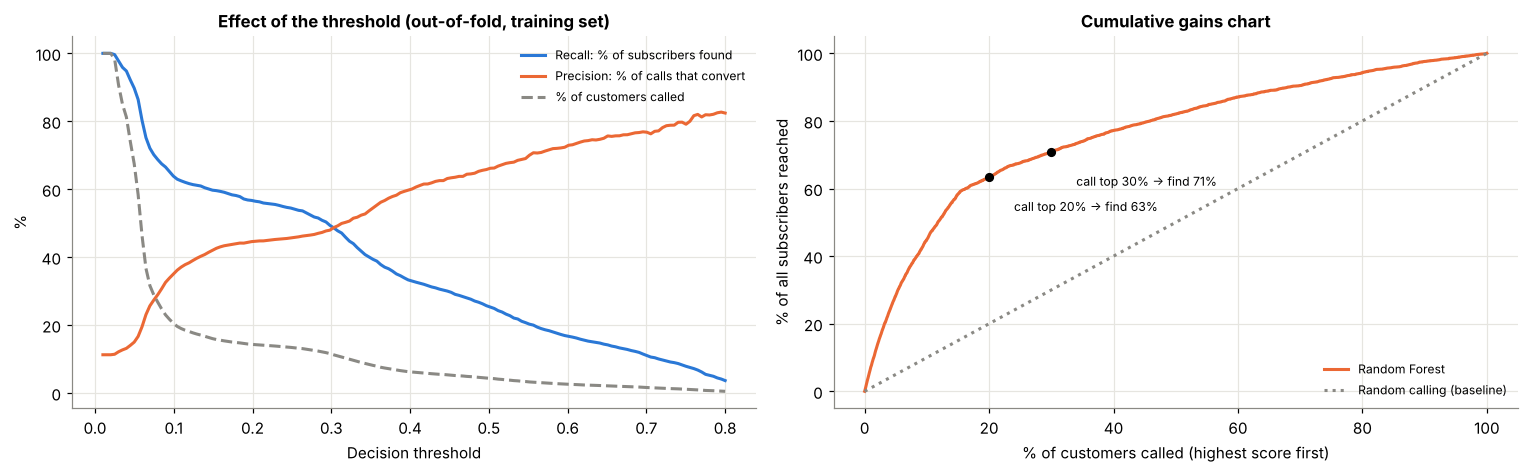

In [26]:
ts = np.linspace(0.01, 0.8, 160)
tt = threshold_table(y_train, oof, ts)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
ax = axes[0]
ax.plot(ts, tt["Recall (% subscribers found)"], color=C["blue"], label="Recall: % of subscribers found")
ax.plot(ts, tt["Precision (% calls that convert)"], color=C["orange"], label="Precision: % of calls that convert")
ax.plot(ts, tt["% customers called"], color=C["grey"], ls="--", label="% of customers called")
ax.set(xlabel="Decision threshold", ylabel="%", title="Effect of the threshold (out-of-fold, training set)")
ax.legend(fontsize=8)

# Cumulative gains: call customers in descending order of predicted probability
order_idx = np.argsort(-oof)
gains = np.cumsum(np.asarray(y_train)[order_idx]) / y_train.sum()
frac = np.arange(1, len(oof) + 1) / len(oof)
ax = axes[1]
ax.plot(frac * 100, gains * 100, color=MODEL_COLORS[best_name], label=best_name)
ax.plot([0, 100], [0, 100], color=C["grey"], ls=":", label="Random calling (baseline)")
for pct in [20, 30]:
    g = gains[int(len(oof) * pct / 100) - 1] * 100
    ax.scatter([pct], [g], color="black", s=25, zorder=4)
    ax.annotate(f"call top {pct}% → find {g:.0f}%", (pct, g), xytext=(pct + 4, g - 10), fontsize=8)
ax.set(xlabel="% of customers called (highest score first)", ylabel="% of all subscribers reached",
       title="Cumulative gains chart")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

### 6.1 Cost-based choice of threshold

Let **c** = cost of one unnecessary call and **b** = net value lost when a subscriber is missed. For a calibrated probability *p*, calling is worthwhile when the expected gain exceeds the expected cost, i.e. when *p · b > (1 − p) · c*, giving the theoretical optimum

$$ t^* = \frac{c}{c + b} = \frac{1}{1 + b/c}. $$

The bank's true costs are not in the data, so we show how the optimal threshold moves with the ratio *b / c* and report the **empirical** cost-minimising threshold from the out-of-fold predictions next to the theoretical value. As an illustrative planning assumption we use **b / c = 8**: a subscription is worth roughly eight times the cost of one phone call (e.g. €40 margin vs €5 per call).

In [27]:
def best_threshold_for_ratio(y_true, proba, ratio, thresholds=np.linspace(0.01, 0.9, 179)):
    y_true = np.asarray(y_true); costs = []
    for t in thresholds:
        pred = proba >= t
        fp = (pred & (y_true == 0)).sum(); fn = (~pred & (y_true == 1)).sum()
        costs.append(fp * 1 + fn * ratio)
    return thresholds[int(np.argmin(costs))], np.array(costs)

rows = []
for r in [2, 4, 6, 8, 10, 15, 20]:
    t_emp, _ = best_threshold_for_ratio(y_train, oof, r)
    rows.append({"b/c (value of subscriber ÷ cost of call)": r, "Theoretical t* = 1/(1+b/c)": 1 / (1 + r),
                 "Empirical cost-minimising threshold": t_emp})
pd.DataFrame(rows).set_index("b/c (value of subscriber ÷ cost of call)").round(3)

,Theoretical t* = 1/(1+b/c),Empirical cost-minimising threshold
b/c (value of subscriber ÷ cost of call),,
2,0.333,0.315
4,0.200,0.165
6,0.143,0.155
8,0.111,0.135
10,0.091,0.090
15,0.062,0.065
20,0.048,0.055


In [28]:
RATIO = 8
t_cost, cost_curve = best_threshold_for_ratio(y_train, oof, RATIO)
f1s = tt["F1"]; t_f1 = f1s.idxmax()
print(f"Cost-optimal threshold (b/c = {RATIO}) on out-of-fold predictions: {t_cost:.3f}")
print(f"F1-optimal threshold on out-of-fold predictions                : {t_f1:.3f}")
RECOMMENDED_T = round(float(t_cost), 2)
print(f"\nRECOMMENDED THRESHOLD: {RECOMMENDED_T}")

Cost-optimal threshold (b/c = 8) on out-of-fold predictions: 0.135
F1-optimal threshold on out-of-fold predictions                : 0.179

RECOMMENDED THRESHOLD: 0.14


### 6.2 Confirming the recommended threshold on the untouched test set

In [29]:
p_best = test_proba[best_name]
compare = threshold_table(y_test, p_best, sorted({0.5, round(float(t_f1), 2), RECOMMENDED_T}))
compare.round(2)

,% customers called,Recall (% subscribers found),Precision (% calls that convert),Calls per subscriber,Unnecessary calls (FP),Missed subscribers (FN),F1
Threshold,,,,,,,
0.14,16.62,63.47,43.02,2.32,780,339,0.51
0.18,14.73,60.78,46.50,2.15,649,364,0.53
0.50,4.29,24.57,64.59,1.55,125,700,0.36


Threshold 0.5:  called 353 of 8,236 customers | subscribers found 228 | missed 700 | unnecessary calls 125 | net value (b/c=8) = 1,471 call-units
Threshold 0.14:  called 1,369 of 8,236 customers | subscribers found 589 | missed 339 | unnecessary calls 780 | net value (b/c=8) = 3,343 call-units


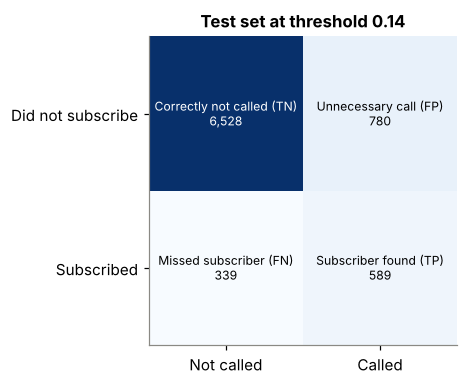

In [30]:
for t in [0.5, RECOMMENDED_T]:
    cm = confusion_matrix(y_test, (p_best >= t).astype(int))
    tn, fp, fn, tp = cm.ravel()
    print(f"Threshold {t}:  called {tp+fp:,} of {len(y_test):,} customers | subscribers found {tp} "
          f"| missed {fn} | unnecessary calls {fp:,} | net value (b/c={RATIO}) = {tp*RATIO - (tp+fp)*1:,.0f} call-units")

cm = confusion_matrix(y_test, (p_best >= RECOMMENDED_T).astype(int))
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.imshow(cm, cmap="Blues"); ax.grid(False)
labels = [["Correctly not called (TN)", "Unnecessary call (FP)"], ["Missed subscriber (FN)", "Subscriber found (TP)"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{labels[i][j]}\n{cm[i, j]:,}", ha="center", va="center", fontsize=8,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Not called", "Called"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["Did not subscribe", "Subscribed"])
ax.set_title(f"Test set at threshold {RECOMMENDED_T}")
plt.tight_layout(); plt.show()

### 6.3 Recommendation and explanation of the trade-off

**Recommended decision threshold: call a customer when the Random Forest predicted probability is ≥ 0.14** (the cost-optimal value for b/c = 8, chosen on out-of-fold training predictions).

Results on the untouched test set (8,236 customers, 928 subscribers):

| Threshold | Customers called | Subscribers found (recall) | Calls that convert (precision) | Unnecessary calls | Missed subscribers | Net value (b/c = 8): 8 × found − calls |
|---|---|---|---|---|---|---|
| 0.50 (default) | 353 (4.3 %) | 228 (24.6 %) | 64.6 % | 125 | 700 | 1,471 call-units |
| **0.14 (recommended)** | **1,369 (16.6 %)** | **589 (63.5 %)** | **43.0 %** | **780** | **339** | **3,343 call-units** |
| Call everyone (no model) | 8,236 (100 %) | 928 (100 %) | 11.3 % | 7,308 | 0 | −812 call-units |

*(Exact values are printed by the cells above; small differences can occur across library versions.)*

* **At the default 0.5** the calls are very "efficient" (65 % convert), but the bank **misses three-quarters of all subscribers** (700 of 928). The rare-event setting pushes almost every probability below 0.5.
* **At 0.14** the bank calls only one customer in six, yet reaches **almost two-thirds of all subscribers**. About 43 % of calls convert, **≈ 3.8× the 11.3 % hit-rate of calling at random**. Compared with 0.5 it finds 361 more subscribers at the price of 1,016 more calls (655 of them unnecessary), i.e. **≈ 2.8 extra calls per extra subscriber**. That is worthwhile whenever a subscriber is worth more than about three calls, and under b/c = 8 the estimated net value more than doubles. Calling everyone would actually *lose* value.
* **The trade-off.** Lowering the threshold always reduces *missed subscribers* (false negatives) and always increases *unnecessary calls* (false positives), and the marginal return falls. Going from 0.14 down to 0.05 would find roughly 25 – 30 percentage points more of the subscribers but require about four times as many calls, with precision falling to ≈ 15 %. The optimum is where the expected value of the next customer on the list, *p · b*, equals the cost of calling them, *(1 − p) · c*. Missing a subscriber (*b*) costs far more than one wasted call (*c*), so the optimum sits well below 0.5. The empirical optimum (0.135) is close to the theoretical *t\** = 1/(1 + 8) = 0.111, which confirms that the forest's probabilities are reasonably calibrated.
* **How to adapt it.** The table in 6.1 is the decision aid. If a subscriber is worth less (b/c ≈ 4), raise the threshold to ≈ 0.17. If worth more (b/c ≈ 15 – 20), lower it to ≈ 0.05 – 0.07. If call-centre capacity is fixed (e.g. 2,000 calls), ignore the probability cut-off and call the top-*k* customers from the gains chart. Customer annoyance, opt-out risk or regulatory contact limits add to *c* and push the threshold up.
* **Validity.** The threshold assumes the probabilities remain calibrated. Section 5.6 shows the base rate changed from ≈ 5 % to ≈ 35 % across periods. Before each campaign the bank should re-check calibration and the threshold on the most recent campaign's results.

## 7. Conclusions and limitations

1. **Data.** 41,176 unique calls with an 11.3 % positive rate. `duration` was removed as target leakage (with it, ROC-AUC would be an unrealistic ≈ 0.95). `"unknown"` was kept as a category and `pdays = 999` recoded.
2. **Baseline.** The majority-class rule gives 88.7 % accuracy but zero recall, ROC-AUC 0.5 and PR-AUC 0.113. This is why accuracy is the wrong metric here.
3. **Models (ranked).** ① **Random Forest**, ② **Logistic Regression**, ③ **Gradient Boosting**. On the random split all three beat the baseline by a wide margin (PR-AUC 0.45 – 0.49 vs 0.11, ROC-AUC 0.80 – 0.82), and the two ensembles are statistically tied. Forward-in-time validation reverses part of this picture: boosting degrades most, because future economic indicators fall outside the training range. Random Forest is the only model that is strong on both criteria.
4. **Threshold.** Use **0.14** rather than 0.5. On the test set it reaches ≈ 64 % of subscribers by calling ≈ 17 % of customers (precision ≈ 43 %), versus 25 % of subscribers at 0.5.

**Limitations and next steps.**
* Cost figures (b/c = 8) are assumptions. They should be replaced with the bank's actual call cost and deposit margin, and the threshold re-read from the table in 6.1.
* Forward-in-time performance (ROC-AUC ≈ 0.56 – 0.58 averaged over rolling folds) is much weaker than the random-split estimate (≈ 0.81). The model learns *when* campaigns succeed as much as *who* subscribes. It should be re-trained on the most recent campaigns and monitored. Features describing economic *change* rather than absolute levels could reduce the extrapolation problem.
* The model is associative, not causal. To estimate the *effect* of calling a customer (uplift), the bank would need a randomised call / no-call experiment.